# Lab 3 — Scale and encode: preparing data for a model — **TEACHER SOLUTION**
**Data Analysis — Master AI / Master RSD** · Chapter 2: sections 6 (Normalisation) and 7 (Encoding)

*Put variables on the same scale, turn text into numbers, without introducing artificial relationships.*

**Lab objectives**
1. **Identify the nature** of each variable (quantitative, nominal, ordinal, target).
2. **Scale** the numeric variables: Z-score, Min-Max, log transform → *choose the suitable method*.
3. **Encode** the categorical variables: One-Hot, Ordinal, Label → *avoid the classic pitfalls*.
4. **Assemble** a reproducible preparation (`ColumnTransformer`) and **measure its effect** on a k-NN model.
5. **Document** every decision in this notebook.

| Duration | Organisation | Data | Deliverable |
|---|---|---|---|
| 2 sessions of 2 h (4 h total) | Pairs · Jupyter notebook | `clients_enriched.csv` (fictional, provided) | Completed notebook + conclusions |

⭐ **Continuity:** `clients_enriched.csv` is the **cleaned file from Lab 2** (988 clients, no missing values), enriched with three categorical variables: `city`, `education`, `satisfaction`.

**How to use**: complete the cells marked `# TODO`, then run the **✅ Self-check** cell that follows. Answer the questions in the **✍️** cells.

## Part 0 — Generating the dataset (teacher)
1. We replay the Lab 2 cleaning on `clients_raw.csv` (duplicates, categories, ages, 999,999 code, k-NN imputation) → 988 clients.
2. We add, with a fixed seed:
   - `city` (**nominal**): Oran, Alger, Constantine, Béchar, Annaba — drawn at random;
   - `education` (**ordinal**): Bachelor < Master < Doctorate — **linked to income** (higher income tends to mean a higher degree);
   - `satisfaction` (**ordinal**): low < medium < high — drawn at random.

In [1]:
import numpy as np
import pandas as pd
from sklearn.impute import KNNImputer

# 1. Lab 2 cleaning
df = pd.read_csv("../TP2/EN/clients_raw.csv", sep=";").drop_duplicates()
df["segment"] = df["segment"].replace({"a": "A", "b": "B"})
df["age"] = pd.to_numeric(df["age"], errors="coerce")
df = df[df["age"].between(0, 120)].copy()
df.loc[df["income"] == 999999, "income"] = np.nan
num = ["age", "income", "n_children", "tenure", "n_purchases"]
df["income"] = KNNImputer(n_neighbors=5).fit_transform(df[num])[:, 1].round(-2)
df = df.sort_values("id").reset_index(drop=True)

# 2. Three categorical variables
rng = np.random.default_rng(2028)              # fixed seed -> identical file on every run
n = len(df)
df["city"] = rng.choice(["Oran", "Alger", "Constantine", "Béchar", "Annaba"], n, p=[.3, .3, .2, .1, .1])
log_inc = np.log(df["income"])
score = (log_inc - log_inc.mean()) / log_inc.std() + rng.normal(0, 1, n)     # income + noise
df["education"] = pd.cut(score, [-np.inf, -0.5, 0.9, np.inf], labels=["Bachelor", "Master", "Doctorate"]).astype(str)
df["satisfaction"] = rng.choice(["low", "medium", "high"], n, p=[.25, .45, .3])

df = df[["id", "age", "income", "n_children", "tenure", "n_purchases",
         "city", "education", "satisfaction", "email", "segment"]]
df.astype({"age": int, "income": int}).to_csv("../TP3/EN/clients_enriched.csv", sep=";", index=False, encoding="utf-8")
print("clients_enriched.csv written:", df.shape)

clients_enriched.csv written: (988, 11)


---
## Setup

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder, LabelEncoder
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

---
## Step 1 — Identify the nature of each variable
*The method depends on the nature **and** the role of the variable* (section 7, good practice ①).

### 1.0 Load the file

In [3]:
df = pd.read_csv("../TP3/EN/clients_enriched.csv", sep=";")

print(df.shape)
df.head()

(988, 11)


,id,age,income,n_children,tenure,n_purchases,city,education,satisfaction,email,segment
0,1,18,49200,2,3,7,Alger,Doctorate,high,client0001@example.dz,C
1,2,87,54900,3,10,12,Alger,Doctorate,high,client0002@example.dz,A
2,3,55,40200,1,13,17,Constantine,Master,low,client0003@example.dz,A
3,4,67,31600,1,11,3,Annaba,Master,medium,client0004@example.dz,C
4,5,40,60300,0,13,17,Béchar,Doctorate,high,client0005@example.dz,A


✅ **Self-check**

In [4]:
assert df.shape == (988, 11), f"Expected (988, 11), got {df.shape} -> separator?"
assert df.isna().sum().sum() == 0, "the file is already clean: no missing values"
print("✅ 1.0 correct")

✅ 1.0 correct


### 1.1 Classify the variables
We want to **predict the client's `segment`** (A, B or C) from the other variables.
For each column, give its nature among: `"identifier"`, `"quantitative"`, `"nominal"`, `"ordinal"`, `"target"`.

💡 Look at the categories with `df["column"].unique()` if in doubt.

In [5]:
for col in ["city", "education", "satisfaction", "segment"]:
    print(f"{col:13s}", sorted(df[col].unique()))

city          ['Alger', 'Annaba', 'Béchar', 'Constantine', 'Oran']
education     ['Bachelor', 'Doctorate', 'Master']
satisfaction  ['high', 'low', 'medium']
segment       ['A', 'B', 'C']


In [6]:
nature = {
    "id":           "identifier",
    "age":          "quantitative",
    "income":       "quantitative",
    "n_children":   "quantitative",
    "tenure":       "quantitative",
    "n_purchases":  "quantitative",
    "city":         "nominal",       # no order between Oran, Alger, Béchar...
    "education":    "ordinal",       # Bachelor < Master < Doctorate
    "satisfaction": "ordinal",       # low < medium < high
    "email":        "identifier",    # unique per client, no useful information
    "segment":      "target",        # what we want to predict
}

✅ **Self-check**

In [7]:
assert nature["city"] == "nominal", "is there a natural order between cities?"
assert nature["education"] == nature["satisfaction"] == "ordinal"
assert nature["segment"] == "target"
assert nature["id"] == nature["email"] == "identifier"
assert all(nature[c] == "quantitative" for c in ["age", "income", "n_children", "tenure", "n_purchases"])
print("✅ 1.1 correct")

✅ 1.1 correct


In [8]:
# These lists are used throughout the lab
num_cols = [c for c, t in nature.items() if t == "quantitative"]
nom_cols = [c for c, t in nature.items() if t == "nominal"]
ord_cols = [c for c, t in nature.items() if t == "ordinal"]
print("numeric:", num_cols)
print("nominal:", nom_cols)
print("ordinal:", ord_cols)

numeric: ['age', 'income', 'n_children', 'tenure', 'n_purchases']
nominal: ['city']
ordinal: ['education', 'satisfaction']


💡 *Useful debate*: `n_children` is an integer with few values (0 to 6). We treat it as **quantitative** (it has a numeric meaning: 4 children = 2 × 2 children), not as a category.

---
## Step 2 — Scaling the numeric variables (section 6)

### 2.1 The problem: different scales
Display the descriptive statistics of the numeric variables. Compare the **range** of `age` and `income`.

In [9]:
display(df[num_cols].describe().round(1))

range_age = df["age"].max() - df["age"].min()
range_income = df["income"].max() - df["income"].min()
print(range_age, range_income, round(range_income / range_age))

,age,income,n_children,tenure,n_purchases
count,988.0,988.0,988.0,988.0,988.0
mean,41.9,44663.7,1.4,10.4,8.8
std,11.8,22579.6,1.2,6.1,4.2
min,18.0,9600.0,0.0,0.0,0.0
25%,33.8,28875.0,1.0,5.0,6.0
50%,42.0,39800.0,1.0,11.0,8.0
75%,50.0,55800.0,2.0,16.0,12.0
max,87.0,185000.0,6.0,20.0,25.0


69 175400 2542


✅ **Self-check**

In [10]:
assert range_age == 69
assert range_income / range_age > 2000, "income varies more than 2000 times as much as age"
print("✅ 2.1 correct")

✅ 2.1 correct


**Expected answer:** a difference of 10,000 DA in income weighs as much as 10,000 years of age! The distance is **crushed by income**; age, tenure or number of purchases hardly count any more. The model no longer "sees" these variables, even when they are informative (we measure this in step 4).

### 2.2 Method 1 — Standardisation (Z-score)
$$z = \frac{x - \mu}{\sigma}$$
1. Compute `income_z` **by hand** with the formula (use `std(ddof=0)`, the population standard deviation, like scikit-learn).
2. Compute it with `StandardScaler` and check you get the same thing.

In [11]:
income_z = (df["income"] - df["income"].mean()) / df["income"].std(ddof=0)

scaler = StandardScaler()
income_z_sk = scaler.fit_transform(df[["income"]]).ravel()

print(round(income_z.mean(), 6), round(income_z.std(ddof=0), 6))

0.0 1.0


✅ **Self-check**

In [12]:
assert np.allclose(income_z, income_z_sk), "the formula and StandardScaler must give the same result"
assert abs(income_z.mean()) < 1e-9 and abs(income_z.std(ddof=0) - 1) < 1e-9, "mean 0, standard deviation 1"
assert np.isclose(scaler.mean_[0], df["income"].mean()), "the scaler stores μ"
print("✅ 2.2 correct")

✅ 2.2 correct


💡 *Point out*: with `std()` (ddof=1, the pandas default) the standard deviation comes out as 0.9995, not 1 → a small difference with scikit-learn, which uses ddof=0.

### 2.3 Method 2 — Min-Max normalisation
$$x' = \frac{x - x_{min}}{x_{max} - x_{min}} \in [0, 1]$$
Same exercise: by hand, then with `MinMaxScaler`.

In [13]:
income_mm = (df["income"] - df["income"].min()) / (df["income"].max() - df["income"].min())
income_mm_sk = MinMaxScaler().fit_transform(df[["income"]]).ravel()

✅ **Self-check**

In [14]:
assert np.allclose(income_mm, income_mm_sk)
assert income_mm.min() == 0 and income_mm.max() == 1
print("✅ 2.3 correct")

✅ 2.3 correct


### 2.4 Log transform: fixing the skewness
Income is **right-skewed** (seen in Lab 2). Z-score and Min-Max **do not change the shape** of the distribution; the logarithm does.

Compute `income_log = np.log1p(income)` ($\log(1+x)$, defined even for $x = 0$), then compare the **skewness** (`skew()`) before / after.

In [15]:
income_log = np.log1p(df["income"])

skew = pd.Series({
    "raw":     df["income"].skew(),
    "Z-score": income_z.skew(),
    "Min-Max": income_mm.skew(),
    "log":     income_log.skew(),
}).round(2)
skew

raw        1.42
Z-score    1.42
Min-Max    1.42
log       -0.08
dtype: float64

✅ **Self-check**

In [16]:
assert skew["raw"] == skew["Z-score"] == skew["Min-Max"], "Z-score and Min-Max keep the shape"
assert abs(skew["log"]) < 0.3 < skew["raw"], "the log makes the distribution almost symmetric"
print("✅ 2.4 correct")

✅ 2.4 correct


Provided cell: the four versions of income side by side (as on the "Compare: Z-score vs Min-Max" slide).

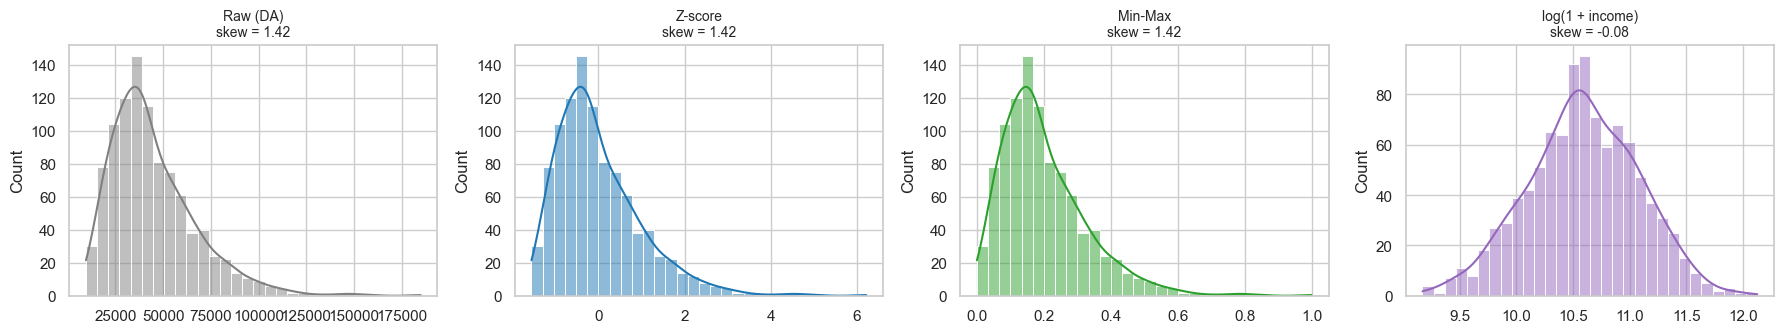

In [17]:
versions = {"Raw (DA)": df["income"], "Z-score": income_z, "Min-Max": income_mm, "log(1 + income)": income_log}
colours = ["gray", "tab:blue", "tab:green", "tab:purple"]

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, (title, series), c in zip(axes, versions.items(), colours):
    sns.histplot(series, bins=30, kde=True, color=c, ax=ax)
    ax.set_title(f"{title}\nskew = {series.skew():.2f}", fontsize=10)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

### 2.5 Sensitivity to extreme values
In Lab 2 we replaced the **999,999** income (a data-entry error) with an imputed value. What would have happened if we had **forgotten**?

On a copy of income where we put **one** value back to 999,999, compute the **median** of the values transformed by Min-Max and by Z-score, with and without the outlier.

In [18]:
with_outlier = df["income"].copy()
with_outlier.iloc[0] = 999999

def minmax(s):
    return (s - s.min()) / (s.max() - s.min())

def zscore(s):
    return (s - s.mean()) / s.std(ddof=0)

effect = pd.DataFrame({
    "without outlier": {"Min-Max median": minmax(df["income"]).median(), "Z-score median": zscore(df["income"]).median()},
    "with outlier": {"Min-Max median": minmax(with_outlier).median(), "Z-score median": zscore(with_outlier).median()},
}).round(3)
effect

,without outlier,with outlier
Min-Max median,0.172,0.030
Z-score median,-0.216,-0.154


✅ **Self-check**

In [19]:
assert effect.loc["Min-Max median", "with outlier"] < 0.05 < effect.loc["Min-Max median", "without outlier"]
print("✅ 2.5 correct")

✅ 2.5 correct


**Expected answers**
1. With the outlier, $x_{max}$ = 999,999: all the other clients are **squeezed** between 0 and ≈ 0.18, half of them below ≈ 0.03. Min-Max is **very sensitive** to extreme values. The Z-score moves too (μ and σ increase), but less abruptly: this is why the course recommends the Z-score when there are outliers.
2. **Income**: skewed with a long tail → **log** to fix the shape, **then Z-score** for the scale. **Age**: roughly symmetric, bounded, no outlier → Z-score (or Min-Max) directly. When in doubt: Z-score.

### 2.6 Good practice: learn μ and σ on the training set only
*"Always compute μ and σ on the training set only. Apply the same transformation to validation, test and new data."*

1. Split `df` into training (80%) and test (20%) with `train_test_split(..., test_size=0.2, random_state=42, stratify=df["segment"])`.
2. `fit` a `StandardScaler` on `num_cols` of the **train set** only, then `transform` both train **and** test.

In [20]:
df_train, df_test = train_test_split(df, test_size=0.2, random_state=42, stratify=df["segment"])

scaler = StandardScaler()
scaler.fit(df_train[num_cols])
X_train_num = scaler.transform(df_train[num_cols])
X_test_num = scaler.transform(df_test[num_cols])

print("train mean:", X_train_num.mean(axis=0).round(3))
print("test mean :", X_test_num.mean(axis=0).round(3))

train mean: [-0. -0. -0.  0. -0.]
test mean : [ 0.076 -0.061  0.041 -0.045  0.013]


✅ **Self-check**

In [21]:
assert len(df_train) == 790 and len(df_test) == 198
assert np.allclose(X_train_num.mean(axis=0), 0), "the train set is centred"
assert not np.allclose(X_test_num.mean(axis=0), 0), "the test set must NOT be exactly centred"
assert np.allclose(scaler.mean_, df_train[num_cols].mean()), "μ learned on the train set only"
print("✅ 2.6 correct")

✅ 2.6 correct


**Expected answer:** the test set is transformed with the μ and σ **of the train set**; its own means are close but not equal. This is intended: the test set plays the role of **new data** that is unknown at training time. Fitting again on the test set (or fitting on the whole dataset before splitting) leaks information from the test set into the model (**data leakage**) and gives an over-optimistic evaluation. In production, clients arrive one at a time: we could not even compute their "mean".

---
## Step 3 — Encoding the categorical variables (section 7)
Reminder of the decision guide: **natural order?** no → **One-Hot**; yes → is it the **target**? yes → **Label**, no → **Ordinal**.

### 3.1 One-Hot Encoding — `city` (nominal)
1. Encode `city` with `pd.get_dummies(..., prefix="city", dtype=int)`.
2. Do it again with `drop_first=True`. How many columns in each case?

In [22]:
city_oh = pd.get_dummies(df["city"], prefix="city", dtype=int)
city_oh_df = pd.get_dummies(df["city"], prefix="city", dtype=int, drop_first=True)

print(city_oh.shape, city_oh_df.shape)
city_oh.head()

(988, 5) (988, 4)


,city_Alger,city_Annaba,city_Béchar,city_Constantine,city_Oran
0,1,0,0,0,0
1,1,0,0,0,0
2,0,0,0,1,0
3,0,1,0,0,0
4,0,0,1,0,0


✅ **Self-check**

In [23]:
assert city_oh.shape == (988, 5), "5 cities -> 5 binary columns"
assert (city_oh.sum(axis=1) == 1).all(), "exactly one 1 per row"
assert city_oh_df.shape == (988, 4)
print("✅ 3.1 correct")

✅ 3.1 correct


**Expected answers**
1. The **first** category in alphabetical order: **Alger**. A client from Alger has **0 everywhere**: it is the reference category. That column was redundant (it can be deduced from the other 4), which bothers some models such as linear regression (collinearity).
2. The model would understand **Oran < Alger < Béchar** and "Béchar = 2 × Alger": an order and distances **that do not exist** (pitfalls ① and ② on the "Classic pitfalls" slide).

### 3.2 Ordinal Encoding — `education` (ordinal)
1. First try `OrdinalEncoder()` **without giving the order** (cell provided): which code does each level get?
2. Fix it by giving the order explicitly: `categories=[["Bachelor", "Master", "Doctorate"]]`.

In [24]:
trap = OrdinalEncoder().fit(df[["education"]])
print("Order learned by default:", list(trap.categories_[0]))

Order learned by default: ['Bachelor', 'Doctorate', 'Master']


In [25]:
enc_education = OrdinalEncoder(categories=[["Bachelor", "Master", "Doctorate"]])
education_code = enc_education.fit_transform(df[["education"]]).ravel()

pd.crosstab(df["education"], education_code)

col_0,0.0,1.0,2.0
education,,,
Bachelor,357,0,0
Doctorate,0,0,257
Master,0,374,0


✅ **Self-check**

In [26]:
codes = pd.Series(education_code, index=df.index).groupby(df["education"]).first()
assert codes["Bachelor"] < codes["Master"] < codes["Doctorate"], "the natural order must be respected"
assert df["income"].corr(pd.Series(education_code, index=df.index)) > 0.4, "education and income are linked"
print("✅ 3.2 correct")

✅ 3.2 correct


**Expected answer:** by default, `OrdinalEncoder` sorts the categories **alphabetically**: Bachelor = 0, Doctorate = 1, Master = 2. The Doctorate ends up **below** the Master! The positive link between education and income would be broken. Good practice: **define the mapping explicitly**. (The same trap applies to `satisfaction`: alphabetically, high < low < medium.)

### 3.3 Label Encoding — `segment` (target)
Encode the target with `LabelEncoder` and display the **learned mapping** (`le.classes_`).

In [27]:
le = LabelEncoder()
y = le.fit_transform(df["segment"])

mapping = dict(zip(le.classes_, le.transform(le.classes_)))
mapping

{'A': np.int64(0), 'B': np.int64(1), 'C': np.int64(2)}

✅ **Self-check**

In [28]:
assert list(le.classes_) == ["A", "B", "C"] and set(y) == {0, 1, 2}
assert (le.inverse_transform(y) == df["segment"]).all(), "we must be able to get the labels back"
print("✅ 3.3 correct")

✅ 3.3 correct


💡 *Reminder*: `LabelEncoder` expects a 1D vector (a single column) and is reserved for the **target y**. For classification, the integers 0, 1, 2 are just **labels**: the model does not compare them.

### 3.4 Pitfall: an unknown category at prediction time
A new client arrives from **Tlemcen**, a city absent from the training data.
1. Provided cell: a default `OneHotEncoder` **crashes**.
2. Create `enc_city` with `handle_unknown="ignore"` and `sparse_output=False`, fit it on `df_train[["city"]]`, then encode the new client.

In [29]:
new_client = pd.DataFrame({"city": ["Tlemcen"]})

try:
    OneHotEncoder().fit(df_train[["city"]]).transform(new_client)
except ValueError as e:
    print("❌ Error:", str(e)[:90], "...")

❌ Error: Found unknown categories ['Tlemcen'] in column 0 during transform ...


In [30]:
enc_city = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(df_train[["city"]])
code_new = enc_city.transform(new_client)

print(enc_city.get_feature_names_out(), code_new)

['city_Alger' 'city_Annaba' 'city_Béchar' 'city_Constantine' 'city_Oran'] [[0. 0. 0. 0. 0.]]


✅ **Self-check**

In [31]:
assert code_new.shape == (1, 5) and code_new.sum() == 0, "unknown city -> all zeros"
print("✅ 3.4 correct")

✅ 3.4 correct


💡 With `handle_unknown="ignore"`, the unknown city is encoded as **all zeros**: the model does not crash and relies on the other variables. Another solution from the course: plan an "Other" category. If a new category becomes frequent, the encoder must be **retrained**.

---
## Step 4 — Assemble the preparation and measure its effect
In a real project, all transformations are grouped in a **`ColumnTransformer`**: each group of columns gets its own treatment, and the same object is applied to train and test (good practice ⑤: *same encoding for training and test*).

### 4.1 The `ColumnTransformer`
Complete `prep`: `StandardScaler` on `num_cols`, `OneHotEncoder` (unknowns ignored) on `nom_cols`, `OrdinalEncoder` with **both** orders on `ord_cols`. `id`, `email` and `segment` are not explanatory variables.

In [32]:
from sklearn.compose import ColumnTransformer

orders = [["Bachelor", "Master", "Doctorate"], ["low", "medium", "high"]]

prep = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("nom", OneHotEncoder(handle_unknown="ignore"), nom_cols),
    ("ord", OrdinalEncoder(categories=orders), ord_cols),
])

X_train = prep.fit_transform(df_train)   # fit on the train set
X_test = prep.transform(df_test)         # transform only on the test set
y_train, y_test = le.transform(df_train["segment"]), le.transform(df_test["segment"])

print(X_train.shape, X_test.shape)
pd.DataFrame(X_train, columns=prep.get_feature_names_out()).head()

(790, 12) (198, 12)


,num__age,num__income,num__n_children,num__tenure,num__n_purchases,nom__city_Alger,nom__city_Annaba,nom__city_Béchar,nom__city_Constantine,nom__city_Oran,ord__education,ord__satisfaction
0,1.200672,0.163882,0.494547,1.548415,0.516976,0.0,1.0,0.0,0.0,0.0,2.0,2.0
1,-1.408188,-1.097400,1.358911,-1.550066,0.280627,0.0,0.0,0.0,0.0,1.0,0.0,1.0
2,-0.314150,-0.386019,-0.369816,0.569947,0.280627,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-0.566620,0.320997,-1.234180,1.548415,1.698722,0.0,0.0,0.0,0.0,1.0,0.0,1.0
4,1.453143,0.181339,-0.369816,-1.060832,0.044278,0.0,0.0,0.0,0.0,1.0,1.0,1.0


✅ **Self-check**

In [33]:
assert X_train.shape == (790, 12) and X_test.shape == (198, 12), "5 numeric + 5 cities + 2 ordinal = 12"
assert "email" not in " ".join(prep.get_feature_names_out()), "email is not an explanatory variable"
print("✅ 4.1 correct")

✅ 4.1 correct


### 4.2 Does scaling change the model?
We predict the `segment` with a **k-NN** (k = 15), a distance-based model. Compare the test **accuracy**:
- **without scaling** the numeric variables (`"passthrough"` instead of the `StandardScaler`);
- with **Z-score**;
- with **Min-Max**.

💡 `Pipeline` chains the preparation and the model: `fit` on the train set, `score` on the test set.

In [34]:
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

def evaluate(scaling):
    """Test accuracy of k-NN (k=15) for a given scaling of the numeric variables."""
    prep = ColumnTransformer([
        ("num", scaling, num_cols),
        ("nom", OneHotEncoder(handle_unknown="ignore"), nom_cols),
        ("ord", OrdinalEncoder(categories=orders), ord_cols),
    ])
    model = Pipeline([("prep", prep), ("knn", KNeighborsClassifier(n_neighbors=15))])
    model.fit(df_train, y_train)
    return model.score(df_test, y_test)

results = pd.Series({
    "None": evaluate("passthrough"),
    "Z-score": evaluate(StandardScaler()),
    "Min-Max": evaluate(MinMaxScaler()),
}, name="accuracy").round(3)
results

None       0.530
Z-score    0.611
Min-Max    0.525
Name: accuracy, dtype: float64

✅ **Self-check**

In [35]:
assert results["Z-score"] > results["None"] + 0.05, "standardisation must clearly improve the k-NN"
print("✅ 4.2 correct")

✅ 4.2 correct


**Expected answer**

| Scaling | Accuracy (test) |
|---|---|
| None | 0.530 |
| Min-Max | 0.525 |
| Z-score | 0.611 |
| log1p + Z-score (bonus) | 0.636 |

- **Without scaling**, the distance is dominated by income (range ≈ 175,000): `n_purchases`, although linked to the segment, hardly counts any more. The Z-score gives each variable a **comparable weight** → **+8 points**.
- **Min-Max** brings the numeric variables into [0, 1], but most incomes end up squeezed between 0 and 0.3 (skewness). Next to them, the one-hot (0/1) and ordinal (0 to 2) columns then weigh **more** than the numeric variables… although the city is drawn at random and only adds **noise**. The Z-score spreads the numeric variables better.
- **Bonus**: the log fixes the skewness of income before the Z-score → distances between incomes become more even → slightly better again (0.636).

```python
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import make_pipeline
evaluate(make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()))
```
(Here the log is applied to all numeric columns; `log1p` accepts the zeros of `n_children`.)

⚠️ An accuracy of 0.6 for 3 classes is modest: the goal is not the model, but to **see the effect of the preparation**. With a decision tree, scaling would have almost no effect ("Which algorithms use what?" slide).

---
## Step 5 — Document every decision
*Good practice ⑥: keep the mapping used, document for reproducibility.*

**Decision log (expected)**

| Variable(s) | Nature | Chosen treatment | Justification |
|---|---|---|---|
| `id`, `email` | identifiers | **excluded** | unique per client: no generalisable information |
| `age`, `n_children`, `tenure`, `n_purchases` | quantitative | **Z-score** (μ, σ learned on train) | different scales; distributions without extreme values |
| `income` | skewed quantitative | **log1p then Z-score** (Z-score alone acceptable) | fixes the right tail; Min-Max would be crushed by an outlier |
| `city` | nominal | **One-Hot**, `handle_unknown="ignore"` | no order between cities; robust to a new city |
| `education`, `satisfaction` | ordinal | **Ordinal** with explicit order | keeps the order in 1 column; alphabetical order would be wrong |
| `segment` | target | **Label Encoding** (A→0, B→1, C→2) | class labels; mapping kept (`le`) to get the letters back |

**Conclusions (example)**
- The numeric variables had very different scales (income ≈ 2,500 × age). Without scaling, k-NN makes more mistakes: standardisation adds ≈ 8 points of accuracy.
- Z-score and Min-Max do not change the shape; only the log fixes income's skewness. Min-Max is fragile with outliers.
- Each encoding follows the nature of the variable; two pitfalls avoided: `OrdinalEncoder`'s alphabetical order and the unknown category at prediction time.
- **Reproducibility**: everything sits in a `ColumnTransformer` learned on the train set and applied as is to the test set and to new clients.

---
## Summary

| Need | Tool | Remember |
|---|---|---|
| Same scale, centred and scaled | `StandardScaler` | default method, less sensitive to outliers |
| Same scale, bounded [0, 1] | `MinMaxScaler` | very sensitive to extreme values |
| Fix skewness | `np.log1p` | changes the **shape**, not just the scale |
| Nominal (no order) | `OneHotEncoder` / `get_dummies` | `handle_unknown="ignore"`, `drop_first` for linear models |
| Ordinal (ordered) | `OrdinalEncoder(categories=...)` | always give the order explicitly |
| Target y | `LabelEncoder` | never for input variables X |
| Put it all together | `ColumnTransformer` + `Pipeline` | `fit` on train, `transform` on test |

**Golden rule:** the model must never interpret an order that does not really exist.